In [97]:
#importing libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json
import joblib
from pathlib import Path
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, average_precision_score)

In [3]:
#importing the data to a DataFrame

df= pd.read_csv("data/fmcg_sales_3years_1M_rows.csv", parse_dates=["date"]) # allows the date column to be read as a real date

In [4]:
#checking first 5 rows of data to confirm data loaded

df.head()

,date,year,month,day,weekofyear,weekday,is_weekend,is_holiday,temperature,rain_mm,...,discount_pct,promo_flag,gross_sales,net_sales,stock_on_hand,stock_out_flag,lead_time_days,supplier_id,purchase_cost,margin_pct
0,2021-01-01,2021,1,1,53,4,0,1,8.44,1.24,...,0.1,1,167.84,151.06,248,0,11,S008,7.53,0.182
1,2021-01-02,2021,1,2,53,5,1,0,12.61,1.12,...,0.0,0,125.88,125.88,238,0,6,S057,5.19,0.505
2,2021-01-03,2021,1,3,53,6,1,0,12.02,2.69,...,0.3,1,398.62,279.03,238,0,6,S017,5.59,0.168
3,2021-01-04,2021,1,4,1,0,0,0,7.76,4.65,...,0.0,0,83.92,83.92,216,0,7,S012,7.81,0.255
4,2021-01-05,2021,1,5,1,1,0,0,11.16,1.77,...,0.2,1,178.33,142.66,372,0,8,S038,7.62,0.073


In [5]:
#checking rows and columns of the data frame

df.shape
print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")

Number of rows: 1100000, Number of columns: 33


In [6]:
#checking column names, data types for the rows

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100000 entries, 0 to 1099999
Data columns (total 33 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   date            1100000 non-null  datetime64[ns]
 1   year            1100000 non-null  int64         
 2   month           1100000 non-null  int64         
 3   day             1100000 non-null  int64         
 4   weekofyear      1100000 non-null  int64         
 5   weekday         1100000 non-null  int64         
 6   is_weekend      1100000 non-null  int64         
 7   is_holiday      1100000 non-null  int64         
 8   temperature     1100000 non-null  float64       
 9   rain_mm         1100000 non-null  float64       
 10  store_id        1100000 non-null  object        
 11  country         1100000 non-null  object        
 12  city            1100000 non-null  object        
 13  channel         1100000 non-null  object        
 14  latitude        11

In [7]:
#checking missing values in each row

df.isna().sum()

date              0
year              0
month             0
day               0
weekofyear        0
weekday           0
is_weekend        0
is_holiday        0
temperature       0
rain_mm           0
store_id          0
country           0
city              0
channel           0
latitude          0
longitude         0
sku_id            0
sku_name          0
category          0
subcategory       0
brand             0
units_sold        0
list_price        0
discount_pct      0
promo_flag        0
gross_sales       0
net_sales         0
stock_on_hand     0
stock_out_flag    0
lead_time_days    0
supplier_id       0
purchase_cost     0
margin_pct        0
dtype: int64

In [8]:
# standardising text labels
text_cols = ["country", "city", "channel", "category", "subcategory", "brand"]
for col in text_cols:
    before = df[col].nunique()
    df[col] = df[col].str.strip()             # remove stray spaces
    print(f"{col:12s} unique labels before/after strip: {before} -> {df[col].nunique()}")

# Always LOOK at the unique values - this is how you spot "E-comm" vs "E-commerce"
print("\nChannels:", sorted(df["channel"].unique()))
print("Countries:", sorted(df["country"].unique()))

country      unique labels before/after strip: 7 -> 7
city         unique labels before/after strip: 9 -> 9
channel      unique labels before/after strip: 4 -> 4
category     unique labels before/after strip: 5 -> 5
subcategory  unique labels before/after strip: 17 -> 17
brand        unique labels before/after strip: 6 -> 6

Channels: ['Convenience', 'E-commerce', 'Hypermarket', 'Supermarket']
Countries: ['Austria', 'France', 'Germany', 'Italy', 'Netherlands', 'Poland', 'Spain']


In [9]:
# how many unique values are present in each of the specified columns
df[["store_id","country","city","channel","brand"]].nunique()

store_id    13
country      7
city         9
channel      4
brand        6
dtype: int64

In [10]:
# checking for impossible values 
print("Negative units:", (df["units_sold"] < 0).sum())
print("Zero or negative price:", (df["list_price"] <= 0).sum())
print("Zero-unit days:", (df["units_sold"] == 0).sum(), f"({(df['units_sold'] == 0).mean():.2%})")
print("Negative margin rows:", (df["margin_pct"] < 0).sum(), "(kept - selling below cost is a business signal)")


Negative units: 0
Zero or negative price: 0
Zero-unit days: 3092 (0.28%)
Negative margin rows: 3570 (kept - selling below cost is a business signal)


In [11]:
# checking first and last dates in the file

print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Number of SKUs:", df["sku_id"].nunique())

First date: 2021-01-01 00:00:00
Last date: 2023-12-31 00:00:00
Number of SKUs: 102


In [12]:
# Missing DAYS: does every store-SKU series have all 1,095 days?
days = df.groupby(["store_id", "sku_id"])["date"].agg(["min", "max", "count"])
short = days[days["count"] < 1095]
print("Stores with gaps:", len(short), "of", len(days))
short   # one store stops early = a product that was discontinued in that store

Stores with gaps: 1 of 1005


,,min,max,count
store_id,sku_id,,,
STORE0013,SKU0073,2021-01-01,2022-09-12,620


In [13]:
# checking that each row is unique per Date +Store Id +SKU ID + Channel
record_key = ["date", "store_id", "sku_id", "channel"]

rows_before_duplicates = len(df)
duplicate_count = df.duplicated(subset=record_key).sum()
print("Repeated rows:", duplicate_count)

df = df.drop_duplicates(subset=record_key, keep="first").copy()
rows_after_duplicates = len(df)
print("Rows before:", rows_before_duplicates)
print("Rows after:", rows_after_duplicates)

Repeated rows: 0
Rows before: 1100000
Rows after: 1100000


In [14]:
# daily demand for each sku 

daily_sku_sales = df.groupby(["date", "sku_id"], as_index=False).agg(
    units_sold=("units_sold", "sum"),
    net_sales=("net_sales", "sum"),
    holiday_market_share=("is_holiday", "mean")
)

display(daily_sku_sales.head())
print("Daily SKU rows and columns:", daily_sku_sales.shape)

,date,sku_id,units_sold,net_sales,holiday_market_share
0,2021-01-01,SKU0001,1118,6976.32,1.0
1,2021-01-01,SKU0002,643,7233.75,1.0
2,2021-01-01,SKU0003,163,518.34,1.0
3,2021-01-01,SKU0004,985,1782.85,1.0
4,2021-01-01,SKU0005,1694,11170.23,1.0


Daily SKU rows and columns: (111690, 5)


In [15]:
# compairing sales across channels 

channel_summary = df.groupby("channel", as_index=False).agg(
    average_units=("units_sold", "mean"),
    total_sales=("net_sales", "sum")
)
channel_summary.sort_values("total_sales", ascending=False).style.format({
        "average_units": "{:,.2f}",
        "total_sales": "{:,.2f}"
    })

,channel,average_units,total_sales
2,Hypermarket,67.24,"258,738,120.70"
1,E-commerce,59.54,"112,734,523.12"
3,Supermarket,47.17,"88,957,659.41"
0,Convenience,35.46,"12,516,149.60"


In [16]:
# checking product revenue

sku_revenue = df.groupby("sku_id").agg(
    total_revenue=("net_sales", "sum"),
    total_units=("units_sold", "sum")
)
sku_revenue = sku_revenue.sort_values("total_revenue", ascending=False)
sku_revenue.head(10)

,total_revenue,total_units
sku_id,,
SKU0018,17032424.64,1173032
SKU0027,16000295.02,1200897
SKU0026,13025419.73,893989
SKU0099,12968809.43,1242389
SKU0092,12496995.90,895842
SKU0100,12351150.68,920354
SKU0064,12326994.00,990120
SKU0061,11967260.40,972948
SKU0028,11749108.59,1253907


In [17]:
# compairing sales across countries 

country_summary = df.groupby("country").agg(
    average_units=("units_sold", "mean"),
    total_sales=("net_sales", "sum")
)
country_summary.sort_values("total_sales", ascending=False).style.format({
        "average_units": "{:,.2f}",
        "total_sales": "{:,.2f}"
    })

,average_units,total_sales
country,,
Italy,55.26,"137,193,076.12"
Spain,55.81,"106,704,767.04"
Germany,67.00,"88,525,559.01"
Austria,65.55,"43,020,025.97"
France,68.66,"42,601,612.57"
Poland,66.90,"42,385,262.52"
Netherlands,35.46,"12,516,149.60"


In [18]:
# promo_flag should be 1 exactly when there is a discount
promo_ok = ((df["promo_flag"] == 1) == (df["discount_pct"] > 0)).mean()
print(f"promo_flag correctly tagged with discount_pct on {promo_ok:.1%} of rows")

# net_sales should equal gross_sales * (1 - discount)
recon = (df["net_sales"] - df["gross_sales"] * (1 - df["discount_pct"])).abs() < 0.05
print(f"net_sales adds up on {recon.mean():.1%} of rows")

promo_flag correctly tagged with discount_pct on 100.0% of rows
net_sales adds up on 100.0% of rows


In [19]:
# stock out days 
avg_units = df.groupby("stock_out_flag")["units_sold"].mean()
stockout_rate = df["stock_out_flag"].mean()

print(f"Average units sold (In Stock):     {avg_units[0]:.1f} units/day")
print(f"Average units sold (Out of Stock): {avg_units[1]:.1f} units/day")
print(f"Percentage of days with a stockout: {stockout_rate:.1%}")

Average units sold (In Stock):     60.7 units/day
Average units sold (Out of Stock): 11.7 units/day
Percentage of days with a stockout: 3.0%


In [20]:
#Overall summary of units sold per store-SKU-day

desc = df["units_sold"].describe().round(1)
print(desc)
print(f"\nTypical daily range (IQR): {desc['25%']} to {desc['75%']} units | Max spike: {desc['max']} units")

count    1100000.0
mean          59.2
std           45.0
min            0.0
25%           25.0
50%           49.0
75%           82.0
max          704.0
Name: units_sold, dtype: float64

Typical daily range (IQR): 25.0 to 82.0 units | Max spike: 704.0 units


In [21]:
# checking lead time days by supplier

supplier_summary = (
    df.groupby("supplier_id", as_index=False)
    .agg(
        skus_supplied=("sku_id", "nunique"),
        min_lead_time=("lead_time_days", "min"),
        avg_lead_time=("lead_time_days", "mean"),
        max_lead_time=("lead_time_days", "max"),
        stockout_rate=("stock_out_flag", "mean")
    )
    .sort_values("avg_lead_time", ascending=False)
)

supplier_summary.style.format({
    "avg_lead_time": "{:.1f} days",
    "stockout_rate": "{:.2%}"
})

,supplier_id,skus_supplied,min_lead_time,avg_lead_time,max_lead_time,stockout_rate
35,S036,102,1,6.6 days,15,3.17%
14,S015,102,1,6.5 days,15,3.04%
47,S048,102,1,6.5 days,15,2.93%
18,S019,102,1,6.5 days,15,2.90%
24,S025,102,1,6.5 days,15,2.98%
58,S059,102,1,6.5 days,16,2.90%
29,S030,102,1,6.5 days,14,2.95%
55,S056,102,1,6.5 days,15,2.75%
21,S022,102,1,6.5 days,15,3.02%
53,S054,102,1,6.5 days,14,2.85%


In [22]:
lead_time_stockouts = (
    df.groupby("lead_time_days", as_index=False)
    .agg(
        total_records=("stock_out_flag", "count"),
        avg_stock_on_hand=("stock_on_hand", "mean"),
        stockout_rate=("stock_out_flag", "mean")
    )
    .sort_values("lead_time_days")
)

lead_time_stockouts.style.format({
    "total_records": "{:,}",
    "avg_stock_on_hand": "{:.1f}",
    "stockout_rate": "{:.2%}"
})

,lead_time_days,total_records,avg_stock_on_hand,stockout_rate
0,1,"6,942",299.1,3.23%
1,2,"18,332",299.9,2.99%
2,3,"48,237",300.1,2.99%
3,4,"100,437",299.5,3.04%
4,5,"165,291",299.4,2.95%
5,6,"210,825",299.5,3.03%
6,7,"211,021",299.4,3.02%
7,8,"164,959",299.3,3.04%
8,9,"100,678",299.3,3.00%
9,10,"48,325",299.4,2.97%


In [23]:
# Overall demand  on weekends and holidays
calendar_summary = (
    df.groupby(["is_weekend", "is_holiday"], as_index=False)
    .agg(
        record_rows=("units_sold", "count"),
        avg_units_sold=("units_sold", "mean"),
        avg_net_sales=("net_sales", "mean"),
        stockout_rate=("stock_out_flag", "mean")
    )
)

calendar_summary["day_type"] = calendar_summary.apply(
    lambda r: f"{'Weekend' if r['is_weekend'] else 'Weekday'} | {'Holiday' if r['is_holiday'] else 'Regular'}",
    axis=1
)

calendar_summary[["day_type", "record_rows", "avg_units_sold", "avg_net_sales", "stockout_rate"]].style.format({
    "record_rows": "{:,}",
    "avg_units_sold": "{:.1f}",
    "avg_net_sales": "{:,.2f}",
    "stockout_rate": "{:.2%}"
})

,day_type,record_rows,avg_units_sold,avg_net_sales,stockout_rate
0,Weekday | Regular,"777,536",56.0,406.82,3.01%
1,Weekday | Holiday,"7,030",57.7,419.05,3.00%
2,Weekend | Regular,"307,396",67.1,487.05,3.01%
3,Weekend | Holiday,"8,038",67.1,493.33,2.77%


In [24]:
# CV for every store-SKU series, then average it by country / channel / category
# compairing volatility between big and small sellers
series = (df.groupby(["store_id", "sku_id"], observed=True)["units_sold"]
            .agg(mean="mean", median="median", std="std")
            .reset_index())
series["cv"] = series["std"] / series["mean"]

# LEFT JOIN: attach country, city, channel to each series (a small 'store' table)
stores = df[["store_id", "country", "city", "channel"]].drop_duplicates()
n_before = len(series)
series = series.merge(stores, on="store_id", how="left")
assert len(series) == n_before, "join created extra rows - check your keys!"   # safety check

cv_country = series.groupby("country", observed=True)["cv"].mean().sort_values(ascending=False).round(3)
cv_channel = series.groupby("channel", observed=True)["cv"].mean().sort_values(ascending=False).round(3)
print("CV by country:\n", cv_country, "\n\nCV by channel:\n", cv_channel)

CV by country:
 country
Netherlands    0.424
Poland         0.418
France         0.417
Germany        0.416
Italy          0.415
Spain          0.414
Austria        0.412
Name: cv, dtype: float64 

CV by channel:
 channel
Convenience    0.424
E-commerce     0.415
Hypermarket    0.415
Supermarket    0.415
Name: cv, dtype: float64


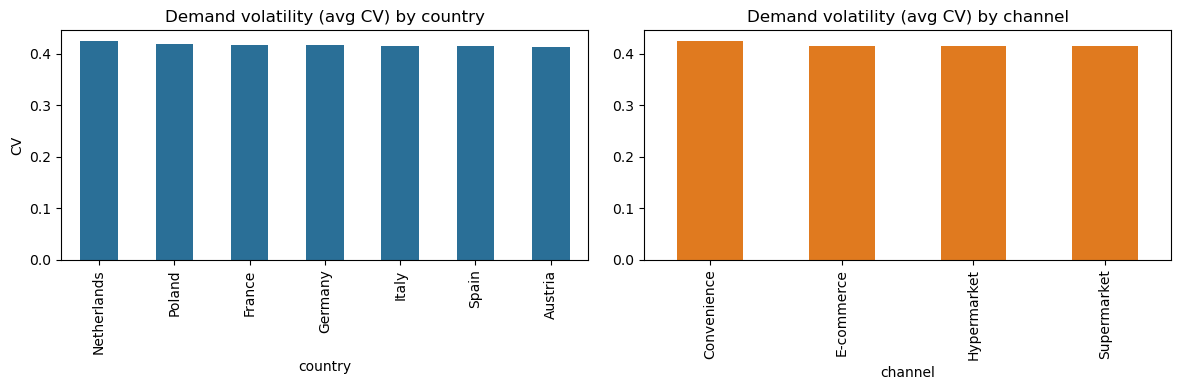

In [25]:
# Chart: volatility by country and channel
FIGS = Path("figs")
FIGS.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cv_country.plot(kind="bar", ax=axes[0], color="#2a6f97")
axes[0].set_title("Demand volatility (avg CV) by country"); axes[0].set_ylabel("CV")
cv_channel.plot(kind="bar", ax=axes[1], color="#e07a1f")
axes[1].set_title("Demand volatility (avg CV) by channel")
plt.tight_layout(); plt.savefig(FIGS / "cv_country_channel.png", dpi=150); plt.show()

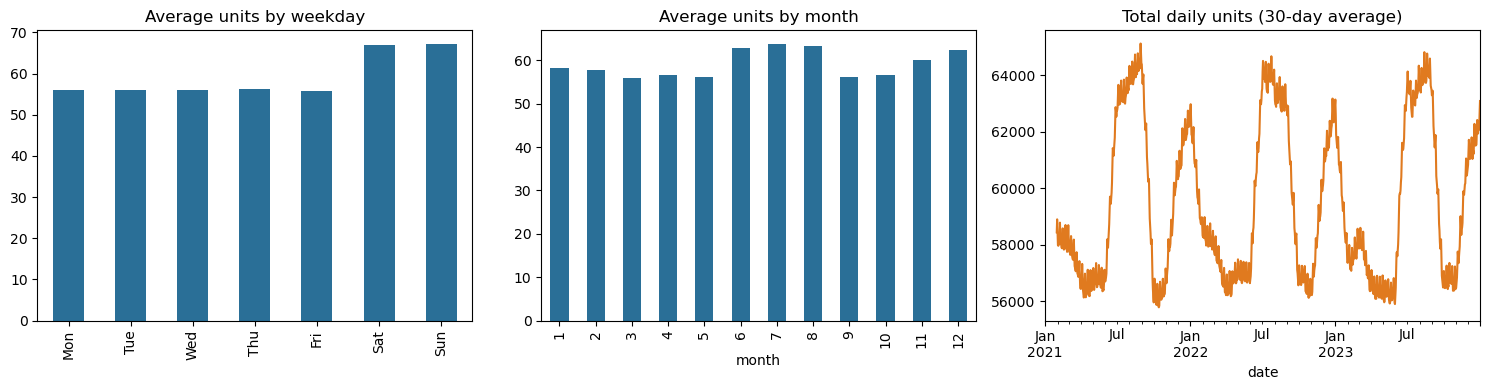

Weekend lift: 19.8%   |   Summer (Jun-Aug) lift: 11.5%


In [26]:
#chart sales by day
daily = df.groupby("date")["units_sold"].sum()               # total units per day, all stores

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
weekday_avg = df.groupby("weekday")["units_sold"].mean()
weekday_avg.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_avg.plot(kind="bar", ax=axes[0], color="#2a6f97"); axes[0].set_title("Average units by weekday")

month_avg = df.assign(month=df["date"].dt.month).groupby("month")["units_sold"].mean()
month_avg.plot(kind="bar", ax=axes[1], color="#2a6f97"); axes[1].set_title("Average units by month")

daily.rolling(30).mean().plot(ax=axes[2], color="#e07a1f")   # 30-day smoothing hides daily noise
axes[2].set_title("Total daily units (30-day average)")
plt.tight_layout(); plt.savefig(FIGS / "seasonality.png", dpi=150); plt.show()

weekend_lift = df[df.weekday >= 5]["units_sold"].mean() / df[df.weekday < 5]["units_sold"].mean() - 1
summer_lift = month_avg.loc[[6, 7, 8]].mean() / month_avg.drop([6, 7, 8, 11, 12]).mean() - 1
print(f"Weekend lift: {weekend_lift:.1%}   |   Summer (Jun-Aug) lift: {summer_lift:.1%}")

In [27]:
# Which categories and channels sell the most per store-day?
print(df.groupby("category", observed=True)["units_sold"].mean().round(1).sort_values(ascending=False))
print(df.groupby("channel", observed=True)["units_sold"].mean().round(1).sort_values(ascending=False))

category
Beverages        68.0
Snacks           63.9
Personal Care    54.2
Home Care        52.4
Dairy            52.2
Name: units_sold, dtype: float64
channel
Hypermarket    67.2
E-commerce     59.5
Supermarket    47.2
Convenience    35.5
Name: units_sold, dtype: float64


In [28]:
# demand by locations 
city = (df.groupby("city", observed=True)
          .agg(latitude=("latitude", "first"), longitude=("longitude", "first"),
               country=("country", "first"),
               units=("units_sold", "sum"), stores=("store_id", "nunique"),
               lead_mean=("lead_time_days", "mean"), lead_std=("lead_time_days", "std"),
               stockout_rate=("stock_out_flag", "mean"))
          .reset_index())
city["units_per_store"] = city["units"] / city["stores"]
city["lead_cv"] = city["lead_std"] / city["lead_mean"]
city.round(3)

,city,latitude,longitude,country,units,stores,lead_mean,lead_std,stockout_rate,units_per_store,lead_cv
0,Amsterdam,52.362,4.958,Netherlands,1730292,1,6.508,2.032,0.030,1730292.0,0.312
1,Barcelona,41.402,2.211,Spain,9424679,2,6.496,2.015,0.029,4712339.5,0.310
2,Berlin,52.526,13.391,Germany,11738571,2,6.505,2.012,0.030,5869285.5,0.309
3,Madrid,40.417,-3.675,Spain,5243338,1,6.512,2.019,0.031,5243338.0,0.310
4,Milan,45.440,9.203,Italy,9126414,2,6.496,2.011,0.030,4563207.0,0.310
5,Paris,48.876,2.360,France,6014974,1,6.500,2.016,0.031,6014974.0,0.310
6,Rome,41.940,12.506,Italy,10235360,2,6.498,2.013,0.030,5117680.0,0.310
7,Vienna,48.203,16.359,Austria,5742174,1,6.494,2.008,0.031,5742174.0,0.309
8,Warsaw,52.253,20.996,Poland,5860180,1,6.506,2.016,0.030,5860180.0,0.310


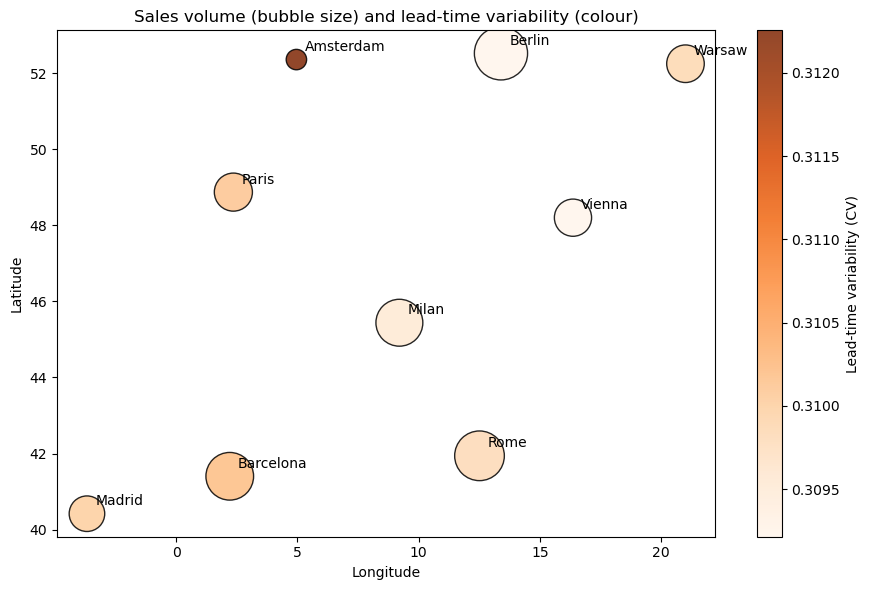

In [29]:
# chart demand by locations
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(city["longitude"], city["latitude"], s=city["units"] / 8000,
                c=city["lead_cv"], cmap="Oranges", edgecolor="k", alpha=0.85)
for _, r in city.iterrows():
    ax.annotate(r["city"], (r["longitude"], r["latitude"]), xytext=(6, 6), textcoords="offset points")
plt.colorbar(sc, label="Lead-time variability (CV)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sales volume (bubble size) and lead-time variability (colour)")
plt.tight_layout(); plt.savefig(FIGS / "geo_bubble_map.png", dpi=150); plt.show()

In [30]:
# "Logistics desert" rule: HIGH demand per store AND HIGH lead-time variability (both above median)
city["desert"] = ((city["units_per_store"] > city["units_per_store"].median()) &
                  (city["lead_cv"] > city["lead_cv"].median()))
print("Possible logistics deserts:", city.loc[city["desert"], "city"].tolist())
print("Spread of lead-time CV across cities:",
      round(city["lead_cv"].min(), 3), "to", round(city["lead_cv"].max(), 3))

Possible logistics deserts: ['Paris']
Spread of lead-time CV across cities: 0.309 to 0.312


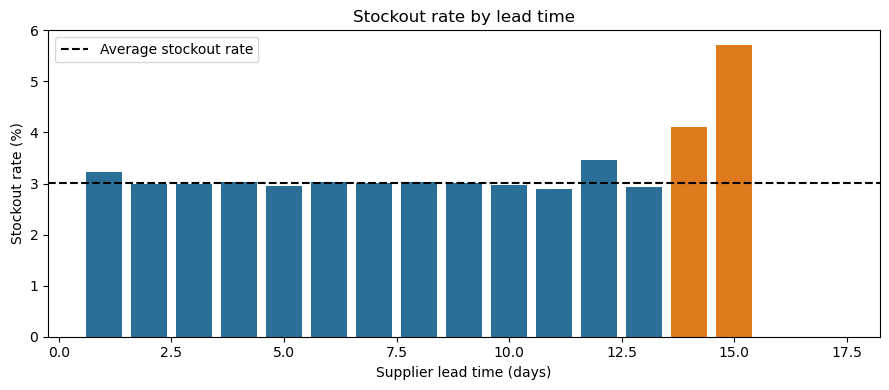

 lead_time_days  stockout_rate   rows
              1         0.0323   6942
              2         0.0299  18332
              3         0.0299  48237
              4         0.0304 100437
              5         0.0295 165291
              6         0.0303 210825
              7         0.0302 211021
              8         0.0304 164959
              9         0.0300 100678
             10         0.0297  48325
             11         0.0290  18307
             12         0.0347   5250
             13         0.0293   1162
             14         0.0410    195
             15         0.0571     35
             16         0.0000      3
             17         0.0000      1

Correlation lead time vs stockout: 0.0002


In [31]:
# does a long lead time cause stockouts?
lt = (df.groupby("lead_time_days")
        .agg(stockout_rate=("stock_out_flag", "mean"), rows=("stock_out_flag", "size"))
        .reset_index())
fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#e07a1f" if d >= 14 else "#2a6f97" for d in lt["lead_time_days"]]
ax.bar(lt["lead_time_days"], lt["stockout_rate"] * 100, color=colors)   # orange = 14+ days (very few rows!)
ax.axhline(df["stock_out_flag"].mean() * 100, ls="--", color="k", label="Average stockout rate")
ax.set_xlabel("Supplier lead time (days)"); ax.set_ylabel("Stockout rate (%)"); ax.legend()
ax.set_title("Stockout rate by lead time")
plt.tight_layout(); plt.savefig(FIGS / "leadtime_vs_stockout.png", dpi=150); plt.show()

print(lt.round(4).to_string(index=False))
corr_lt = df[["lead_time_days", "stock_out_flag"]].corr().iloc[0, 1]
print("\nCorrelation lead time vs stockout:", round(corr_lt, 4))

In [32]:
#ABC/XYZ segmentation
CUTOFF = "2023-07-01"   # 1 July 2023 (matches df["date"] format)
ABC_A, ABC_B = 0.80, 0.95
XYZ_X, XYZ_Y = 0.50, 1.00

train = df[df["date"] < CUTOFF]            # only data before 1 July 2023
print("Training days:", train["date"].nunique())

# --- ABC ---
sku_rev = (train.groupby("sku_id", observed=True)["net_sales"].sum()
                .sort_values(ascending=False).reset_index())
sku_rev["share"] = sku_rev["net_sales"] / sku_rev["net_sales"].sum()
sku_rev["cum_share"] = sku_rev["share"].cumsum()
# np.select picks the first matching rule for each row
sku_rev["abc"] = np.select([sku_rev["cum_share"] <= ABC_A, sku_rev["cum_share"] <= ABC_B], ["A", "B"], "C")

# --- XYZ --- (CV of total daily units per SKU)
daily_sku = train.groupby(["sku_id", "date"], observed=True)["units_sold"].sum()
cv_sku = (daily_sku.groupby("sku_id", observed=True).std() / daily_sku.groupby("sku_id", observed=True).mean())
cv_sku = cv_sku.rename("cv").reset_index()
cv_sku["xyz"] = np.select([cv_sku["cv"] < XYZ_X, cv_sku["cv"] < XYZ_Y], ["X", "Y"], "Z")

# combine with a LEFT JOIN
sku_class = sku_rev.merge(cv_sku, on="sku_id", how="left")
sku_class["sku_id"] = sku_class["sku_id"].astype(str)
sku_class["segment"] = sku_class["abc"] + sku_class["xyz"]
print(sku_class.head())

Training days: 911
    sku_id    net_sales     share  cum_share abc        cv xyz segment
0  SKU0018  14114006.28  0.036027   0.036027   A  0.234997   X      AX
1  SKU0027  13159963.41  0.033592   0.069620   A  0.327286   X      AX
2  SKU0026  10741528.52  0.027419   0.097038   A  0.170215   X      AX
3  SKU0099  10741059.68  0.027418   0.124456   A  0.338883   X      AX
4  SKU0092  10412754.30  0.026580   0.151036   A  0.139032   X      AX


Number of SKUs:
 xyz   X
abc    
A    49
B    29
C    24 

Share of revenue:
 xyz      X
abc       
A    0.794
B    0.156
C    0.050


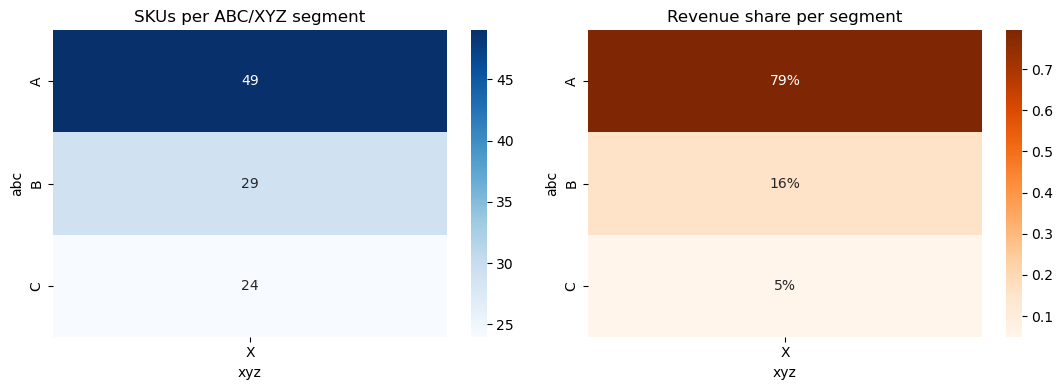

In [33]:
# The 3x3 grid: how many SKUs fall in each segment, and how much revenue they carry
grid_count = pd.crosstab(sku_class["abc"], sku_class["xyz"])
grid_rev = (sku_class.pivot_table(index="abc", columns="xyz", values="share", aggfunc="sum")
            .fillna(0).round(3))
print("Number of SKUs:\n", grid_count, "\n\nShare of revenue:\n", grid_rev)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(grid_count, annot=True, fmt="d", cmap="Blues", ax=axes[0]); axes[0].set_title("SKUs per ABC/XYZ segment")
sns.heatmap(grid_rev, annot=True, fmt=".0%", cmap="Oranges", ax=axes[1]); axes[1].set_title("Revenue share per segment")
plt.tight_layout(); plt.savefig(FIGS / "abc_xyz_grid.png", dpi=150); plt.show()

In [34]:
# Join the segment labels back onto the sales rows (LEFT JOIN + row check)
slim = df[["sku_id", "country", "channel", "net_sales"]].copy()
slim["sku_id"] = slim["sku_id"].astype(str)
n_before = len(slim)
slim = slim.merge(sku_class[["sku_id", "abc", "xyz"]], on="sku_id", how="left")
assert len(slim) == n_before and slim["abc"].notna().all()
print("Revenue by ABC class:\n", (slim.groupby("abc")["net_sales"].sum() / slim["net_sales"].sum()).round(3))


Revenue by ABC class:
 abc
A    0.794
B    0.156
C    0.050
Name: net_sales, dtype: float64


In [35]:
tr = train[["sku_id", "country", "net_sales"]].copy()
tr["sku_id"] = tr["sku_id"].astype(str)
rev_cs = tr.groupby(["country", "sku_id"], observed=True)["net_sales"].sum().reset_index()
rev_cs = rev_cs.sort_values(["country", "net_sales"], ascending=[True, False])
rev_cs["cum_share"] = rev_cs.groupby("country")["net_sales"].transform(lambda s: s.cumsum() / s.sum())
rev_cs["abc"] = np.select([rev_cs["cum_share"] <= ABC_A, rev_cs["cum_share"] <= ABC_B], ["A", "B"], "C")

abc_by_country = rev_cs.pivot(index="sku_id", columns="country", values="abc")
n_countries = abc_by_country.notna().sum(axis=1)
differs = abc_by_country.nunique(axis=1) > 1          # class changes between countries
print("SKUs sold in several countries:", int((n_countries > 1).sum()))
print("SKUs whose ABC class DIFFERS between countries:", int(differs.sum()))
abc_by_country[differs].head(10)

SKUs sold in several countries: 102
SKUs whose ABC class DIFFERS between countries: 37


country,Austria,France,Germany,Italy,Netherlands,Poland,Spain
sku_id,,,,,,,
SKU0004,B,B,C,B,NaN,B,C
SKU0006,B,B,C,B,B,C,B
SKU0007,A,A,A,A,NaN,A,B
SKU0009,A,A,B,A,B,A,A
SKU0010,A,B,B,B,NaN,B,B
SKU0011,B,B,C,B,NaN,B,B
SKU0012,B,B,B,A,NaN,B,B
SKU0014,B,NaN,B,A,B,B,C
SKU0016,B,NaN,B,B,NaN,B,A


In [36]:
# Biggest swings: A in one country but C in another
swing = abc_by_country[(abc_by_country == "A").any(axis=1) & (abc_by_country == "C").any(axis=1)]
print("SKUs that are 'A' somewhere and 'C' elsewhere:", len(swing))

SKUs that are 'A' somewhere and 'C' elsewhere: 5


In [37]:
train = df[df["date"] < CUTOFF]
test = df[df["date"] >= CUTOFF]
print(f"Train: {train['date'].min().date()} -> {train['date'].max().date()}  ({len(train):,} rows)")
print(f"Test : {test['date'].min().date()} -> {test['date'].max().date()}  ({len(test):,} rows)")
print("Promo share train vs test:", round(train["promo_flag"].mean(), 3), round(test["promo_flag"].mean(), 3))

Train: 2021-01-01 -> 2023-06-30  (915,264 rows)
Test : 2023-07-01 -> 2023-12-31  (184,736 rows)
Promo share train vs test: 0.08 0.08


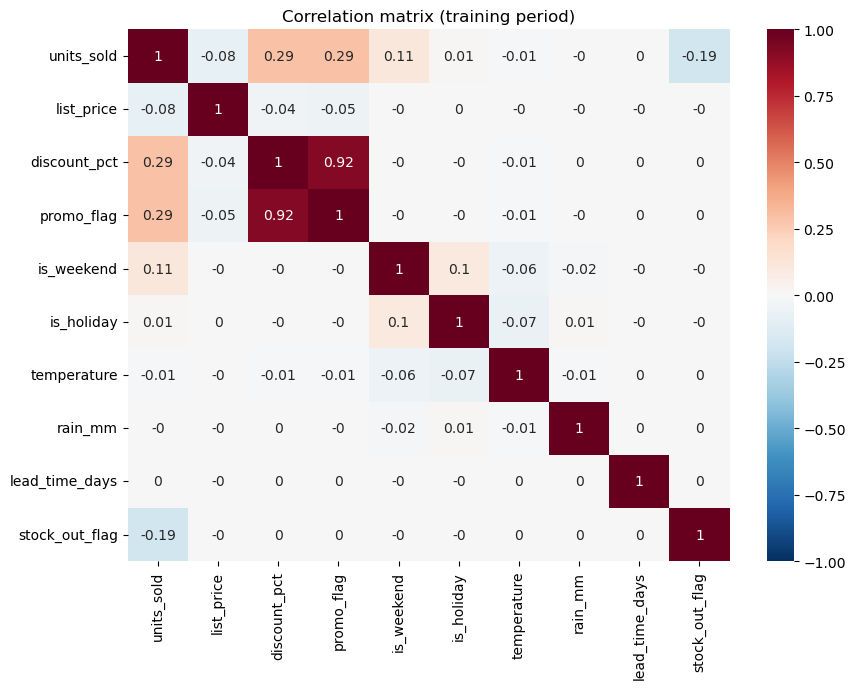

units_sold        1.00
discount_pct      0.29
promo_flag        0.29
is_weekend        0.11
is_holiday        0.01
rain_mm          -0.00
lead_time_days    0.00
temperature      -0.01
list_price       -0.08
stock_out_flag   -0.19
Name: units_sold, dtype: float64


In [38]:
#correlation matrix
cols = ["units_sold", "list_price", "discount_pct", "promo_flag", "is_weekend", "is_holiday",
        "temperature", "rain_mm", "lead_time_days", "stock_out_flag"]
corr = train[cols].corr().round(2)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (training period)")
plt.tight_layout(); plt.savefig(FIGS / "correlation_matrix.png", dpi=150); plt.show()

print(corr["units_sold"].sort_values(ascending=False))

In [39]:
#the list of Category A SKUs from your ABC classification
a_skus = sku_class.loc[sku_class["abc"] == "A", "sku_id"]

#hypothesis test
#H0 --> promo days have the same sales as non promo days
#H1 --> promo days have higher sales

a_train = train[train["sku_id"].isin(a_skus)]              # A products, training period only
promo = a_train.loc[a_train["promo_flag"] == 1, "units_sold"]
base = a_train.loc[a_train["promo_flag"] == 0, "units_sold"]
print("A-product promo days:", len(promo), "| non-promo days:", len(base))
print("Mean units  promo vs normal:", round(promo.mean(), 1), "vs", round(base.mean(), 1))
print("Skewness of sales (0 = symmetric):", round(stats.skew(base), 2))

A-product promo days: 35115 | non-promo days: 403987
Mean units  promo vs normal: 128.8 vs 67.5
Skewness of sales (0 = symmetric): 0.82


In [41]:
train = df[df["date"] < CUTOFF]
test = df[df["date"] >= CUTOFF]
print(f"Train: {train['date'].min().date()} -> {train['date'].max().date()}  ({len(train):,} rows)")
print(f"Test : {test['date'].min().date()} -> {test['date'].max().date()}  ({len(test):,} rows)")
print("Promo share train vs test:", round(train["promo_flag"].mean(), 3), round(test["promo_flag"].mean(), 3))

# From here on, all statistics use the TRAIN period only, so the test period stays untouched.

Train: 2021-01-01 -> 2023-06-30  (915,264 rows)
Test : 2023-07-01 -> 2023-12-31  (184,736 rows)
Promo share train vs test: 0.08 0.08


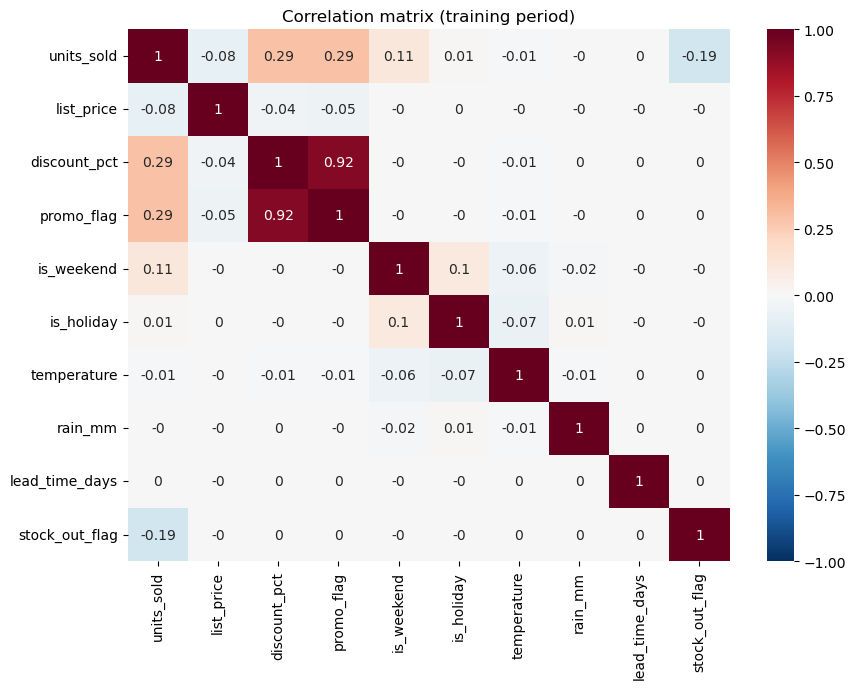

units_sold        1.00
discount_pct      0.29
promo_flag        0.29
is_weekend        0.11
is_holiday        0.01
rain_mm          -0.00
lead_time_days    0.00
temperature      -0.01
list_price       -0.08
stock_out_flag   -0.19
Name: units_sold, dtype: float64


In [48]:
cols = ["units_sold", "list_price", "discount_pct", "promo_flag", "is_weekend", "is_holiday",
        "temperature", "rain_mm", "lead_time_days", "stock_out_flag"]
corr = train[cols].corr().round(2)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix (training period)")
plt.tight_layout(); plt.savefig(FIGS / "correlation_matrix.png", dpi=150)
plt.show()

print(corr["units_sold"].sort_values(ascending=False))


In [43]:
a_train = train[train["sku_id"].isin(a_skus)]              # A products, training period only
promo = a_train.loc[a_train["promo_flag"] == 1, "units_sold"]
base = a_train.loc[a_train["promo_flag"] == 0, "units_sold"]
print("A-product promo days:", len(promo), "| non-promo days:", len(base))
print("Mean units  promo vs normal:", round(promo.mean(), 1), "vs", round(base.mean(), 1))
print("Skewness of sales (0 = symmetric):", round(stats.skew(base), 2))

A-product promo days: 35115 | non-promo days: 403987
Mean units  promo vs normal: 128.8 vs 67.5
Skewness of sales (0 = symmetric): 0.82


In [46]:
#Run the statistical tests
u_stat, p_mw = stats.mannwhitneyu(promo, base, alternative="greater")
t_stat, p_t = stats.ttest_ind(promo, base, equal_var=False, alternative="greater")

#Calculate the percentage lift
lift = (promo.mean() - base.mean()) / base.mean()

print(f"Promo lift: {lift:.1%}")
print(f"Mann-Whitney p-value: {p_mw:.4e}")
print(f"Welch t-test p-value: {p_t:.4e}")

#if/else check for significance
if p_mw < 0.05:
    print("Result: Significant! Promotions increase sales volume.")
else:
    print("Result: Not significant.")

Promo lift: 90.8%
Mann-Whitney p-value: 0.0000e+00
Welch t-test p-value: 0.0000e+00
Result: Significant! Promotions increase sales volume.


In [51]:
# Split the data into normal days and promo days
normal_days = a_train[a_train["promo_flag"] == 0]
promo_days = a_train[a_train["promo_flag"] == 1].copy()

#Calculate each store-SKU's average normal sales (baseline)
baseline = (
    normal_days.groupby(["store_id", "sku_id"], observed=True)["units_sold"]
    .mean()
    .reset_index(name="baseline")
)

#Attach the baseline to each promo day and calculate the lift ratio
promo_days = promo_days.merge(baseline, on=["store_id", "sku_id"], how="left")
promo_days["ratio"] = promo_days["units_sold"] / promo_days["baseline"]

# Drop any rows where baseline was missing
valid_ratios = promo_days["ratio"].dropna()

#Run Wilcoxon signed-rank test (checks if ratio > 1, meaning lift > 0%)
w_stat, p_w = stats.wilcoxon(valid_ratios - 1, alternative="greater")

print(f"Median ratio (promo / own baseline): {valid_ratios.median():.2f}")
print(f"Wilcoxon p-value: {p_w:.4e}")

#Calculate 95% confidence interval using a standard for-loop (bootstrap)
rng = np.random.default_rng(42)
ratios_array = valid_ratios.to_numpy()

boot_means = []
for _ in range(300):
    sample = rng.choice(ratios_array, size=len(ratios_array))
    boot_means.append(sample.mean())

ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
print(f"Average promo ratio: {ratios_array.mean():.2f} (95% CI: {ci_low:.2f} - {ci_high:.2f})")

Median ratio (promo / own baseline): 1.82
Wilcoxon p-value: 0.0000e+00
Average promo ratio: 1.86 (95% CI: 1.85 - 1.86)


SKUs that are ever promoted: 41 of 102
Promoted A-SKUs: 20 of 49
   discount_pct   mean    size  lift_vs_normal
0          0.00   67.5  403987          -0.000
1          0.10  117.5    8819           0.741
2          0.15  124.0    9009           0.837
3          0.20  131.6    8948           0.949
4          0.30  142.9    8339           1.117


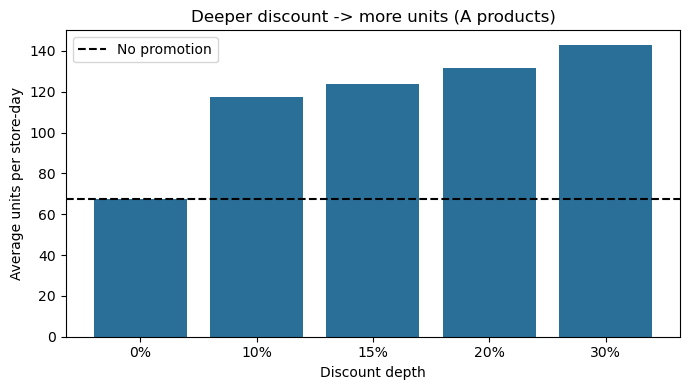

In [53]:
# which SKUs get promotions?
promoted = train.loc[train["promo_flag"] == 1, "sku_id"].astype(str).unique()
print("SKUs that are ever promoted:", len(promoted), "of", train["sku_id"].nunique())
print("Promoted A-SKUs:", len(set(promoted) & set(a_skus)), "of", len(a_skus))

depth = (a_train.groupby("discount_pct")["units_sold"].agg(["mean", "size"]).round(1).reset_index())
depth["lift_vs_normal"] = (depth["mean"] / base.mean() - 1).round(3)
print(depth)

plt.figure(figsize=(7, 4))
plt.bar((depth["discount_pct"] * 100).astype(int).astype(str) + "%", depth["mean"], color="#2a6f97")
plt.axhline(base.mean(), ls="--", color="k", label="No promotion")
plt.ylabel("Average units per store-day"); plt.xlabel("Discount depth"); plt.legend()
plt.title("Deeper discount -> more units (A products)")
plt.tight_layout(); plt.savefig(FIGS / "promo_depth.png", dpi=150)
plt.show()

In [54]:
#price changes 
x = a_train[(a_train["units_sold"] > 0) & (a_train["stock_out_flag"] == 0)].copy()
x["log_units"] = np.log(x["units_sold"])
x["log_price"] = np.log(x["list_price"] * (1 - x["discount_pct"]))      # effective shelf price

# remove each SKU's average to compare a SKU only with itself ("within-SKU")
for c in ["log_units", "log_price"]:
    x[c + "_dm"] = x[c] - x.groupby("sku_id", observed=True)[c].transform("mean")

# (a) all days: price cut vs no price cut (mixes price and promotion effects)
res_all = stats.linregress(x["log_price_dm"], x["log_units_dm"])
# (b) promo days only: does a DEEPER cut sell more? (pure price-depth effect)
xp = x[x["promo_flag"] == 1]
res_depth = stats.linregress(xp["log_price_dm"], xp["log_units_dm"])

print(f"(a) Elasticity, all days        : {res_all.slope:6.2f}   (mixes price + promo effect)")
print(f"(b) Elasticity, promo days only : {res_depth.slope:6.2f}   (depth of discount only)")

(a) Elasticity, all days        :  -2.53   (mixes price + promo effect)
(b) Elasticity, promo days only :  -0.82   (depth of discount only)


In [55]:
#how does promo affect future sales?
g = train.groupby(["store_id", "sku_id"], observed=True)["promo_flag"]
# 1 if there was any promotion in the previous 7 days (shift(1) = yesterday)
train = train.assign(promo_last7=g.transform(lambda s: s.shift(1).rolling(7, min_periods=1).max()))
after = train[(train["promo_flag"] == 0) & (train["promo_last7"] == 1)]["units_sold"].mean()
normal = train[(train["promo_flag"] == 0) & (train["promo_last7"] == 0)]["units_sold"].mean()
print(f"Avg units in the 7 days after a promo: {after:.1f}   vs normal non-promo days: {normal:.1f}")
print(f"Difference: {after / normal - 1:.1%}")

Avg units in the 7 days after a promo: 55.3   vs normal non-promo days: 54.9
Difference: 0.7%


In [57]:
# How do weekends and holidays affect sales?
for col in ["is_weekend", "is_holiday"]:
    # Split sales into event days (1) vs. regular days (0)
    event_sales = train.loc[train[col] == 1, "units_sold"]
    regular_sales = train.loc[train[col] == 0, "units_sold"]

    # Calculate averages and percentage lift
    avg_event = event_sales.mean()
    avg_regular = regular_sales.mean()
    lift = (avg_event - avg_regular) / avg_regular

    # Take equal-sized random samples (max 100,000) so the test runs fast
    sample_size = min(len(event_sales), len(regular_sales), 100_000)
    event_sample = event_sales.sample(sample_size, random_state=1)
    regular_sample = regular_sales.sample(sample_size, random_state=1)

    # Run Mann-Whitney U test and print results
    u_stat, p_value = stats.mannwhitneyu(event_sample, regular_sample)
    print(f"{col:11s} | yes: {avg_event:.1f}, no: {avg_regular:.1f} | lift: {lift:.1%} | p-value: {p_value:.4e}")

is_weekend  | yes: 66.8, no: 55.8 | lift: 19.6% | p-value: 0.0000e+00
is_holiday  | yes: 63.7, no: 58.9 | lift: 8.2% | p-value: 4.1792e-13


In [62]:
# Set the target number of SKUs to pick
N_SKUS = 10

# 1. Sort all SKUs from highest to lowest net sales
ranked = sku_class.sort_values("net_sales", ascending=False)

# 2. Pick up to 3 top-selling SKUs from each available segment (3 segments x 3 = 9 SKUs)
picked = ranked.groupby("segment").head(3)

# 3. If we still have fewer than 10 SKUs, fill the remaining spots with the next highest-selling SKUs
remaining_needed = N_SKUS - len(picked)
if remaining_needed > 0:
    not_picked = ~ranked["sku_id"].isin(picked["sku_id"])
    extra = ranked[not_picked].head(remaining_needed)
    selected = pd.concat([picked, extra])
else:
    selected = picked.head(N_SKUS)

# 4. Sort the final 10 SKUs by net sales
selected = selected.sort_values("net_sales", ascending=False)

# 5. Look up product names and categories from the main dataframe
names = df[["sku_id", "sku_name", "category"]].drop_duplicates().copy()
names["sku_id"] = names["sku_id"].astype(str)

# 6. Merge the names in and display the final clean table
selected = selected.merge(names, on="sku_id", how="left")
cols_to_show = ["sku_id", "sku_name", "category", "segment", "cv", "net_sales"]
selected[cols_to_show].round(3)

,sku_id,sku_name,category,segment,cv,net_sales
0,SKU0018,BrandF Water,Beverages,AX,0.235,14114006.28
1,SKU0027,BrandC Chips,Snacks,AX,0.327,13159963.41
2,SKU0026,BrandB Chips,Snacks,AX,0.170,10741528.52
3,SKU0099,BrandC Toothpaste,Personal Care,AX,0.339,10741059.68
4,SKU0080,BrandB Cleaner,Home Care,BX,0.344,2568116.12
5,SKU0090,BrandF Shampoo,Personal Care,BX,0.144,2468727.93
6,SKU0010,BrandD Juice,Beverages,BX,0.396,2463390.20
7,SKU0056,BrandB Milk,Dairy,CX,0.338,1295164.44
8,SKU0084,BrandF Cleaner,Home Care,CX,0.132,1254777.93
9,SKU0022,BrandD Energy drink,Beverages,CX,0.243,1251365.16


In [63]:
SELECTED_SKUS = selected["sku_id"].tolist()
print(SELECTED_SKUS)

['SKU0018', 'SKU0027', 'SKU0026', 'SKU0099', 'SKU0080', 'SKU0090', 'SKU0010', 'SKU0056', 'SKU0084', 'SKU0022']


In [64]:
#aggregate SKUs to channel + day
d = df[df["sku_id"].astype(str).isin(SELECTED_SKUS)].copy()
d["sku_id"] = d["sku_id"].astype(str)
d["channel"] = d["channel"].astype(str)

daily = (d.groupby(["sku_id", "channel", "date"], observed=True)
           .agg(units=("units_sold", "sum"),                 # TARGET: what we want to forecast
                net_sales=("net_sales", "sum"),
                n_stores=("store_id", "nunique"),
                promo_share=("promo_flag", "mean"),           # share of stores running a promo that day
                avg_discount=("discount_pct", "mean"),
                stockout_share=("stock_out_flag", "mean"),
                lead_time=("lead_time_days", "mean"),
                is_holiday=("is_holiday", "max"))
           .reset_index()
           .sort_values(["sku_id", "channel", "date"])        # sorting by time is REQUIRED for lags
           .reset_index(drop=True))
print(daily.shape)
print("Series (SKU x channel):", daily.groupby(["sku_id", "channel"]).ngroups)
daily.head()

(40515, 11)
Series (SKU x channel): 37


,sku_id,channel,date,units,net_sales,n_stores,promo_share,avg_discount,stockout_share,lead_time,is_holiday
0,SKU0010,E-commerce,2021-01-01,89,627.45,3,0.0,0.00,0.0,6.666667,1
1,SKU0010,E-commerce,2021-01-02,238,1426.21,3,1.0,0.15,0.0,6.000000,0
2,SKU0010,E-commerce,2021-01-03,207,1167.48,3,1.0,0.20,0.0,7.000000,0
3,SKU0010,E-commerce,2021-01-04,96,676.80,3,0.0,0.00,0.0,8.000000,0
4,SKU0010,E-commerce,2021-01-05,123,867.15,3,0.0,0.00,0.0,5.333333,0


In [65]:
# Check every series has every day (no gaps), otherwise lags would point at the wrong day
days_per_series = daily.groupby(["sku_id", "channel"]).size()
print(days_per_series.describe()[["min", "max"]])
print("Series shorter than 1095 days:", int((days_per_series < 1095).sum()))

min    1095.0
max    1095.0
dtype: float64
Series shorter than 1095 days: 0


In [67]:
# Forecast horizon in days (adjust this if your notebook uses a different value, e.g., 14)
HORIZON = 7

# 1. Build a clean, sorted list of lag days (always at least HORIZON days back to avoid data leakage)
candidate_lags = [1, 7, 14, 30, HORIZON, HORIZON + 7, HORIZON + 14]
lags = sorted({lag for lag in candidate_lags if lag >= HORIZON})
print(f"Horizon: {HORIZON} days -> lags used: {lags}")

# 2. Group by each SKU + channel series so lags/rolling windows never cross series
grouped = daily.groupby(["sku_id", "channel"])

# 3. Create lag features for units sold
for lag in lags:
    daily[f"lag_{lag}"] = grouped["units"].shift(lag)

# 4. Shift by HORIZON first so rolling averages only use past known days, then take rolling means
shifted_units = grouped["units"].shift(HORIZON)
daily["roll_mean_7"] = shifted_units.groupby([daily["sku_id"], daily["channel"]]).transform(
    lambda s: s.rolling(7).mean()
)
daily["roll_mean_28"] = shifted_units.groupby([daily["sku_id"], daily["channel"]]).transform(
    lambda s: s.rolling(28).mean()
)

# 5. Create lagged stockout and lead-time features (again shifted by HORIZON)
daily["stockout_lag"] = grouped["stockout_share"].shift(HORIZON)
daily["lead_time_lag"] = grouped["lead_time"].shift(HORIZON)

Horizon: 7 days -> lags used: [7, 14, 21, 30]


In [68]:
daily["weekday"] = daily["date"].dt.weekday                      # 0 = Monday
daily["is_weekend"] = (daily["weekday"] >= 5).astype(int)
daily["month"] = daily["date"].dt.month
daily["is_month_start"] = daily["date"].dt.is_month_start.astype(int)
daily["is_month_end"] = daily["date"].dt.is_month_end.astype(int)
# sine/cosine make December and January "close" to each other (a circle, not a line)
daily["doy_sin"] = np.sin(2 * np.pi * daily["date"].dt.dayofyear / 365.25)
daily["doy_cos"] = np.cos(2 * np.pi * daily["date"].dt.dayofyear / 365.25)

In [69]:
# promo_share and avg_discount are already in the table from the aggregation above.
daily[["promo_share", "avg_discount"]].describe().round(3)

,promo_share,avg_discount
count,40515.000,40515.000
mean,0.103,0.019
std,0.304,0.062
min,0.000,0.000
25%,0.000,0.000
50%,0.000,0.000
75%,0.000,0.000
max,1.000,0.300


In [70]:
# Test 1: lag_14 on a given day must equal units exactly 14 days earlier
one = daily[(daily["sku_id"] == SELECTED_SKUS[0]) & (daily["channel"] == "Hypermarket")].reset_index(drop=True)
row = 200
assert one.loc[row, f"lag_{HORIZON}"] == one.loc[row - HORIZON, "units"], "lag is pointing at the wrong day!"
print(f"OK: lag_{HORIZON} on row {row} equals units from row {row - HORIZON}")

# Test 2: the rolling mean must NOT include recent days
expected = one.loc[row - HORIZON - 6: row - HORIZON, "units"].mean()
assert abs(one.loc[row, "roll_mean_7"] - expected) < 1e-9
print("OK: roll_mean_7 only uses days older than the horizon")

# Test 3: no feature should ever be today's units or today's stockout
print("Features never include today's units/stockout - only lags of them.")

OK: lag_7 on row 200 equals units from row 193
OK: roll_mean_7 only uses days older than the horizon
Features never include today's units/stockout - only lags of them.


In [86]:
#Define lag days and set cutoff_date to hold out the final 90 days for testing
LAGS = [7, 14, 21]
cutoff_date = model_df["date"].max() - pd.Timedelta(days=90)

#Group lag column names clearly
lag_cols = [f"lag_{lag}" for lag in LAGS]

#Group all numeric feature names together
other_numeric_cols = [
    "roll_mean_7", "roll_mean_28", "stockout_lag", "lead_time_lag",
    "promo_share", "avg_discount", "n_stores",
    "is_holiday", "is_weekend", "is_month_start", "is_month_end",
    "weekday", "month", "doy_sin", "doy_cos"
]

NUMERIC = lag_cols + other_numeric_cols
CATEGORICAL = ["channel", "sku_id"]

#Drop early warm-up rows where lag values are still missing (NaN)
model_df = daily.dropna(subset=NUMERIC).reset_index(drop=True)
print(f"Rows before/after dropping warm-up weeks: {len(daily):,} -> {len(model_df):,}")

#Split chronologically into training and test sets
train = model_df[model_df["date"] < cutoff_date].copy()
test = model_df[model_df["date"] >= cutoff_date].copy()

print(f"Train {train['date'].min().date()} -> {train['date'].max().date()}: {len(train):,} rows")
print(f"Test  {test['date'].min().date()} -> {test['date'].max().date()}: {len(test):,} rows")

Rows before/after dropping warm-up weeks: 40,515 -> 39,257
Train 2021-02-04 -> 2023-10-01: 35,890 rows
Test  2023-10-02 -> 2023-12-31: 3,367 rows


In [87]:
#Select the lag feature column and create the scaler
lag_col = f"lag_{HORIZON}"
scaler = StandardScaler()

#Fit the scaler ONLY on training data to avoid data leakage
train_values = train[[lag_col]]
scaler.fit(train_values)

train_mean = scaler.mean_[0]
train_std = scaler.scale_[0]
print(f"Learned from train -> mean: {train_mean:.1f}, std: {train_std:.1f}")

#Apply the already-fitted scaler to the test set (and check row count first)
if len(test) == 0:
    print("Warning: 'test' has 0 rows. Adjust CUTOFF to an earlier date before scaling.")
else:
    test_values = test[[lag_col]]
    test_scaled = scaler.transform(test_values)
    print(f"Scaled {len(test_scaled):,} test rows | test scaled mean: {test_scaled.mean():.3f}")

Learned from train -> mean: 186.8, std: 187.1
Scaled 3,367 test rows | test scaled mean: -0.010


In [88]:
try:
    from statsmodels.tsa.stattools import adfuller

    rows = []
    for sku, part in train.groupby("sku_id"):
        series = part.groupby("date")["units"].sum()            # total daily units of this SKU
        p_level = adfuller(series, autolag="AIC")[1]            # [1] = the p-value
        p_diff = adfuller(series.diff().dropna(), autolag="AIC")[1]
        rows.append({"sku_id": sku, "p_value": round(p_level, 4),
                     "stationary": p_level < 0.05, "p_after_differencing": round(p_diff, 4)})
    adf = pd.DataFrame(rows)
    print(adf.to_string(index=False))
except ImportError:
    print("statsmodels is not installed -> run: pip install statsmodels   (then re-run this cell)")

 sku_id  p_value  stationary  p_after_differencing
SKU0010   0.0182        True                   0.0
SKU0018   0.0340        True                   0.0
SKU0022   0.0302        True                   0.0
SKU0026   0.0301        True                   0.0
SKU0027   0.0000        True                   0.0
SKU0056   0.0000        True                   0.0
SKU0080   0.0000        True                   0.0
SKU0084   0.0000        True                   0.0
SKU0090   0.0000        True                   0.0
SKU0099   0.0000        True                   0.0


In [89]:
def forecast_metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    err = pred - actual
    nonzero = actual > 0                                   # MAPE cannot divide by zero
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE_%": np.mean(np.abs(err[nonzero]) / actual[nonzero]) * 100,
            "WAPE_%": np.sum(np.abs(err)) / np.sum(actual) * 100,
            "Bias_%": np.sum(err) / np.sum(actual) * 100}

In [90]:
# 1. Define features and target column
FEATURES = NUMERIC + CATEGORICAL
TARGET = "units"

# 2. Build feature matrices (X) and target vectors (y) from train and test sets
X_train = train[FEATURES]
y_train = train[TARGET]
X_test = test[FEATURES]

# 3. Collect baseline predictions on the test set
results = {}
results[f"Naive ({HORIZON} days ago)"] = test[f"lag_{HORIZON}"].to_numpy()
results["28-day average"] = test["roll_mean_28"].to_numpy()

# 4. Preprocess numeric and categorical features inside a Pipeline (fitted on train only)
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
])

model = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression()),
])

# 5. Train the model and store test predictions
model.fit(X_train, y_train)
results["Linear Regression"] = model.predict(X_test)

print("Models trained and predictions stored:", list(results.keys()))

Models trained and predictions stored: ['Naive (7 days ago)', '28-day average', 'Linear Regression']


In [94]:
# Set a fixed random seed for reproducible results
RANDOM_STATE = 42

#Sort training rows by date for time-series cross-validation
train_sorted = train.sort_values("date")
Xs = train_sorted[FEATURES]
ys = train_sorted["units"]

#Create a 3-fold time-series split (never leaks future dates into past folds)
tscv = TimeSeriesSplit(n_splits=3)

#Build Random Forest pipeline using the existing preprocessor
rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

#Build HistGradientBoosting pipeline and tune learning rate and tree depth
hgb_base = Pipeline([
    ("prep", preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=300,
        random_state=RANDOM_STATE,
    )),
])

param_grid = {
    "model__learning_rate": [0.03, 0.08],
    "model__max_depth": [3, 6],
}

grid = GridSearchCV(
    hgb_base,
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)

#Fit the grid search and grab the best gradient boosting model
grid.fit(Xs, ys)
hgb = grid.best_estimator_

print("Best Gradient Boosting settings:", grid.best_params_)

Best Gradient Boosting settings: {'model__learning_rate': 0.03, 'model__max_depth': 6}


In [95]:
# Fair comparison of the models on the TRAIN period only (validation scores)
cv_scores = {}
for name, model in [("Linear Regression", lin), ("Random Forest", rf), ("Gradient Boosting", hgb)]:
    s = -cross_val_score(model, Xs, ys, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)
    cv_scores[name] = s.mean()
cv_table = pd.Series(cv_scores).round(2).rename("validation MAE")
print(cv_table)

final_name = cv_table.idxmin()                           # the final model is chosen on VALIDATION, not on test
print("\nFinal model chosen on validation data:", final_name)

Linear Regression    41.75
Random Forest        30.68
Gradient Boosting    30.14
Name: validation MAE, dtype: float64

Final model chosen on validation data: Gradient Boosting


In [99]:
# Fit the advanced models on the full training set and generate test predictions
rf.fit(X_train, y_train)
hgb.fit(X_train, y_train)

results["Random Forest"] = rf.predict(X_test)
results["Gradient Boosting"] = hgb.predict(X_test)

#Define the output folder and create it if it does not exist yet
PROCESSED = Path("data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

#Map model names to fitted models and save the winner chosen in Cell [95]
fitted = {
    "Linear Regression": lin,
    "Random Forest": rf,
    "Gradient Boosting": hgb,
}

model_path = PROCESSED / "final_model.joblib"
joblib.dump(fitted[final_name], model_path)
print(f"Saved '{final_name}' model to {model_path}")

Saved 'Gradient Boosting' model to data\processed\final_model.joblib


In [101]:
#Define the actual target values for the test set
y_test = test["units"]

#Compute evaluation metrics for each model stored in `results`
rows = {}
for model_name, predictions in results.items():
    rows[model_name] = forecast_metrics(y_test, predictions)

#Turn the results into a clean table sorted from lowest to highest MAE
comparison = pd.DataFrame.from_dict(rows, orient="index").round(2)
comparison = comparison.sort_values("MAE")
comparison

,MAE,RMSE,MAPE_%,WAPE_%,Bias_%
Random Forest,28.92,47.59,26.65,15.51,-0.03
Gradient Boosting,28.97,47.66,27.38,15.54,-0.10
Linear Regression,40.34,65.39,49.35,21.64,-1.15
28-day average,43.91,80.35,31.97,23.55,-1.22
Naive (7 days ago),57.25,105.53,40.34,30.71,-0.80


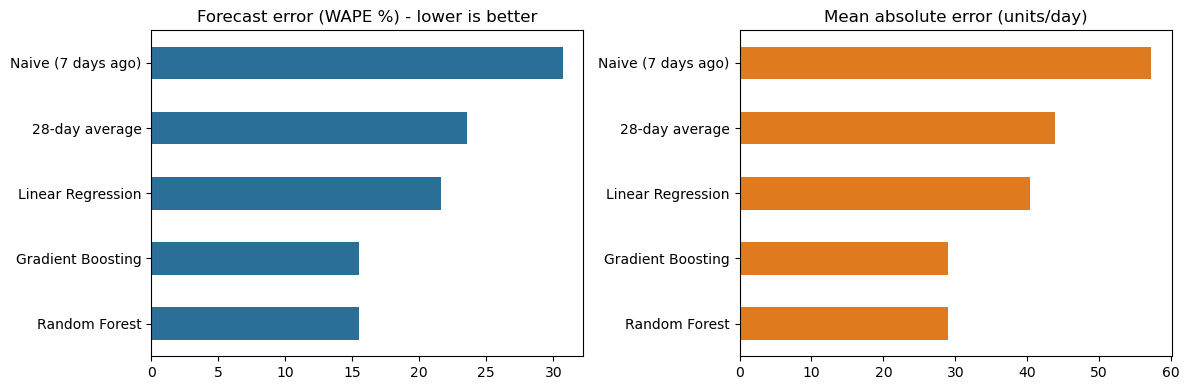

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["WAPE_%"].plot(kind="barh", ax=axes[0], color="#2a6f97"); axes[0].set_title("Forecast error (WAPE %) - lower is better")
comparison["MAE"].plot(kind="barh", ax=axes[1], color="#e07a1f"); axes[1].set_title("Mean absolute error (units/day)")
plt.tight_layout(); plt.savefig(FIGS / "model_comparison.png", dpi=150)
plt.show()

In [105]:
# Save predictions
pred_table = test[["date", "sku_id", "channel", "units"]].copy()
for name, pred in results.items():
    pred_table[name] = pred
pred_table.to_pickle(PROCESSED / "predictions.pkl")

In [108]:
#Get SKU -> segment mapping directly from the in-memory `sku_class` DataFrame
seg_map = sku_class.set_index("sku_id")["segment"]

#Automatically find the naive baseline column name in `pred_table`
naive_cols = [col for col in pred_table.columns if col.startswith("Naive (")]
if not naive_cols:
    raise KeyError(f"No 'Naive (...)' column found in pred_table. Available columns: {list(pred_table.columns)}")
naive_col = naive_cols[0]

#Compute forecast metrics per SKU for the winning model vs. the naive baseline
rows = []
for sku, part in pred_table.groupby("sku_id"):
    m_best = forecast_metrics(part["units"], part[final_name])
    m_naive = forecast_metrics(part["units"], part[naive_col])

    rows.append({
        "sku_id": sku,
        "segment": seg_map.get(sku, "Unknown"),
        "avg_units_per_day": part["units"].mean(),
        "MAE": m_best["MAE"],
        "RMSE": m_best["RMSE"],
        "MAPE_%": m_best["MAPE_%"],
        "WAPE_%": m_best["WAPE_%"],
        "Bias_%": m_best["Bias_%"],
        "Naive_WAPE_%": m_naive["WAPE_%"],
    })

#Build and display the sorted per-SKU summary table
per_sku = pd.DataFrame(rows).sort_values(["segment", "sku_id"]).round(2)
per_sku

,sku_id,segment,avg_units_per_day,MAE,RMSE,MAPE_%,WAPE_%,Bias_%,Naive_WAPE_%
1,SKU0018,AX,308.20,41.90,56.79,19.18,13.59,1.99,19.43
3,SKU0026,AX,233.04,36.53,52.24,43.93,15.67,-2.20,21.27
4,SKU0027,AX,313.87,52.32,82.10,25.35,16.67,-2.58,37.79
9,SKU0099,AX,293.81,42.45,60.09,21.30,14.45,1.11,42.13
0,SKU0010,BX,118.39,20.07,28.09,18.98,16.95,-1.76,36.53
6,SKU0080,BX,173.54,32.62,47.70,45.26,18.80,1.61,39.06
8,SKU0090,BX,47.97,7.68,11.35,31.83,16.01,1.83,22.97
2,SKU0022,CX,279.10,40.75,53.42,16.85,14.60,0.38,20.94
5,SKU0056,CX,70.37,9.30,13.49,20.08,13.22,0.51,33.48
7,SKU0084,CX,62.56,10.05,13.87,24.35,16.07,0.69,22.47


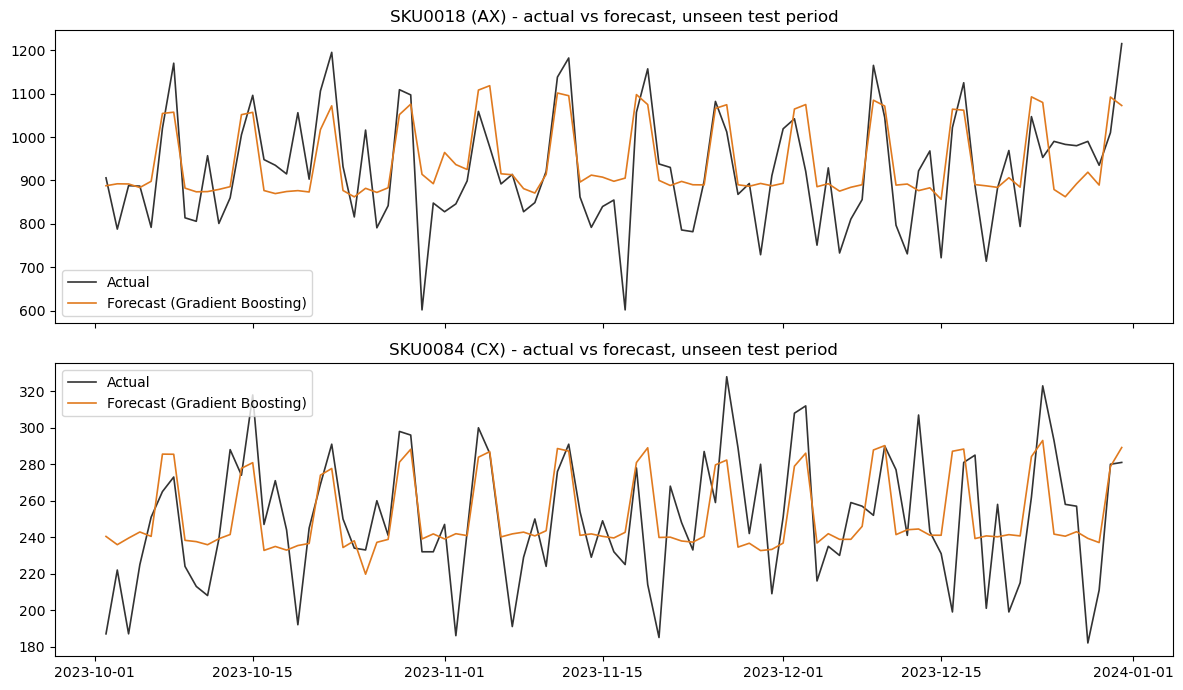

In [110]:
#Pick the first and last SKUs from sorted per_sku summary table
skus_to_plot = [
    per_sku.iloc[0]["sku_id"],
    per_sku.iloc[-1]["sku_id"],
]

#Make sure the output folder for figures exists
FIGS = Path("reports/figures")
FIGS.mkdir(parents=True, exist_ok=True)

#Plot actual vs. forecast daily units (summed across channels) for each SKU
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for ax, sku in zip(axes, skus_to_plot):
    daily_sku = (
        pred_table[pred_table["sku_id"] == sku]
        .groupby("date")[["units", final_name]]
        .sum()
    )
    segment_label = seg_map.get(sku, "Unknown")

    ax.plot(daily_sku.index, daily_sku["units"], label="Actual", color="#333", lw=1.2)
    ax.plot(daily_sku.index, daily_sku[final_name], label=f"Forecast ({final_name})", color="#e07a1f", lw=1.2)
    ax.set_title(f"{sku} ({segment_label}) - actual vs forecast, unseen test period")
    ax.legend()

plt.tight_layout()
plt.savefig(FIGS / "forecast_vs_actual.png", dpi=150)
plt.show()

In [112]:
inner = model.named_steps["model"]
names = model.named_steps["prep"].get_feature_names_out()          # includes one-hot columns
if hasattr(inner, "feature_importances_"):
    imp = pd.Series(inner.feature_importances_, index=names).sort_values(ascending=False)
    print(imp.head(12).round(3))
else:
    print("This model has no built-in importance - use the permutation method below.")

This model has no built-in importance - use the permutation method below.


In [113]:
groups = {
    "Momentum (lags + rolling averages)": [c for c in NUMERIC if c.startswith(("lag_", "roll_mean"))],
    "Promotions (share, discount depth)": ["promo_share", "avg_discount"],
    "Calendar (weekday, month, holiday...)": ["weekday", "month", "is_weekend", "is_holiday",
                                              "is_month_start", "is_month_end", "doy_sin", "doy_cos"],
    "Supply signals (stockout, lead time)": ["stockout_lag", "lead_time_lag"],
    "Identity (SKU, channel, store count)": ["sku_id", "channel", "n_stores"],
}

X_test, y_test = test[FEATURES], test["units"].to_numpy()
base_mae = np.mean(np.abs(model.predict(X_test) - y_test))
rng = np.random.default_rng(RANDOM_STATE)

rows = []
for group, cols in groups.items():
    increases = []
    for _ in range(5):                                      # repeat 5 times, then average
        shuffled = X_test.copy()
        order = rng.permutation(len(shuffled))              # one shuffle applied to ALL columns of the group
        shuffled[cols] = X_test[cols].iloc[order].to_numpy()
        increases.append(np.mean(np.abs(model.predict(shuffled) - y_test)) - base_mae)
    rows.append({"feature_group": group, "mae_increase": np.mean(increases)})

perm = pd.DataFrame(rows).sort_values("mae_increase", ascending=False)
perm["share_of_total_%"] = (perm["mae_increase"] / perm["mae_increase"].sum() * 100).round(1)
perm["mae_increase"] = perm["mae_increase"].round(2)
print("Baseline MAE:", round(base_mae, 2))
perm

Baseline MAE: 28.97


,feature_group,mae_increase,share_of_total_%
0,Momentum (lags + rolling averages),136.65,81.4
1,"Promotions (share, discount depth)",18.82,11.2
4,"Identity (SKU, channel, store count)",7.08,4.2
2,"Calendar (weekday, month, holiday...)",5.30,3.2
3,"Supply signals (stockout, lead time)",0.05,0.0


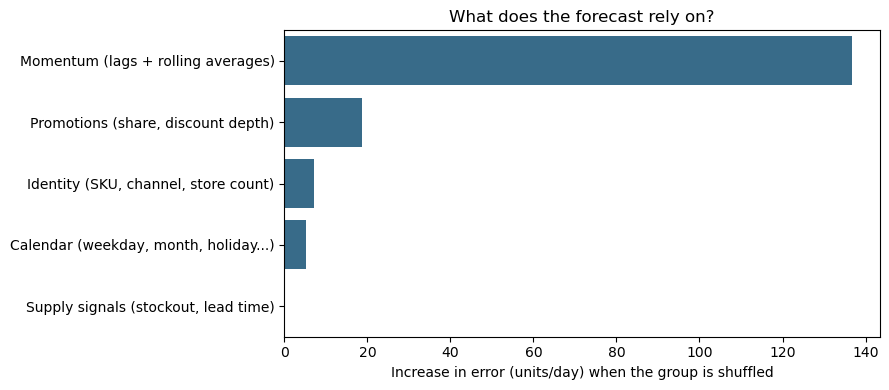

In [114]:
plt.figure(figsize=(9, 4))
sns.barplot(data=perm, y="feature_group", x="mae_increase", color="#2a6f97")
plt.xlabel("Increase in error (units/day) when the group is shuffled"); plt.ylabel("")
plt.title("What does the forecast rely on?")
plt.tight_layout()
plt.savefig(FIGS / "feature_importance_groups.png", dpi=150)
plt.show()

In [116]:
# Check whether the winning model underserves smaller sales channels
def channel_report(frame, pred_col):
    rows = []

    for channel_name, group in frame.groupby("channel"):
        error = group[pred_col] - group["units"]
        total_actual = group["units"].sum()

        rows.append({
            "channel": channel_name,
            "avg_units_per_day": group["units"].mean(),
            "WAPE_%": (error.abs().sum() / total_actual) * 100,
            "Bias_%": (error.sum() / total_actual) * 100,
            "days_under_forecast_%": (error < 0).mean() * 100,
        })

    report = pd.DataFrame(rows).round(2).set_index("channel")
    return report

fair = channel_report(pred_table, final_name)
fair

,avg_units_per_day,WAPE_%,Bias_%,days_under_forecast_%
channel,,,,
Convenience,40.51,25.68,3.69,43.17
E-commerce,161.31,18.35,-0.70,51.76
Hypermarket,364.38,12.85,-0.09,50.11
Supermarket,135.73,17.31,-0.20,51.65


Convenience  bias 95% interval: [0.6, 7.41]
E-commerce   bias 95% interval: [-2.34, 1.0]
Hypermarket  bias 95% interval: [-1.25, 1.26]
Supermarket  bias 95% interval: [-1.82, 1.35]


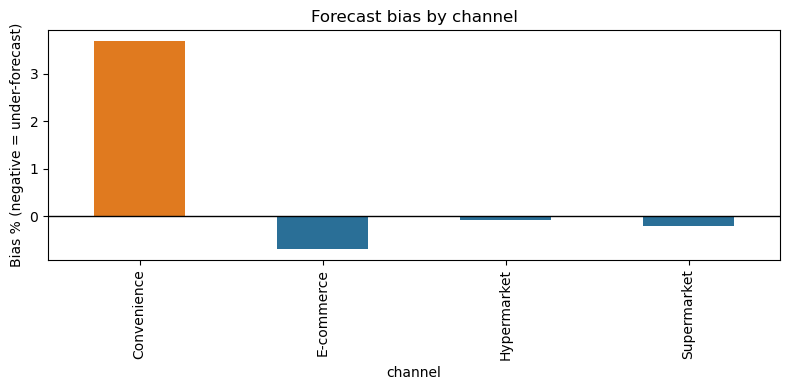

In [118]:
rng = np.random.default_rng(42)

#Function to estimate a 95% confidence interval for Bias % using bootstrapping
def bias_ci(frame, n=300):
    errors = (frame[final_name] - frame["units"]).to_numpy()
    actuals = frame["units"].to_numpy()
    indices = np.arange(len(errors))

    bootstrap_biases = []
    for _ in range(n):
        sample_idx = rng.choice(indices, size=len(indices), replace=True)
        bias_pct = (errors[sample_idx].sum() / actuals[sample_idx].sum()) * 100
        bootstrap_biases.append(bias_pct)

    return np.percentile(bootstrap_biases, [2.5, 97.5]).round(2)

#Print the 95% bias interval for each sales channel using `pred_table`
for channel_name, group in pred_table.groupby("channel"):
    ci_low, ci_high = bias_ci(group)
    print(f"{channel_name:12s} bias 95% interval: [{ci_low}, {ci_high}]")

#Plot forecast bias by channel and highlight Convenience
bar_colors = ["#e07a1f" if ch == "Convenience" else "#2a6f97" for ch in fair.index]

fig, ax = plt.subplots(figsize=(8, 4))
fair["Bias_%"].plot(kind="bar", ax=ax, color=bar_colors)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Bias % (negative = under-forecast)")
ax.set_title("Forecast bias by channel")

plt.tight_layout()
plt.savefig(FIGS / "bias_by_channel.png", dpi=150)
plt.show()

In [120]:
#Set a default service-level Z-score (1.65 ≈ 95% service level) if not already defined
if "SERVICE_Z" not in globals():
    SERVICE_Z = 1.65

#Merge lead time from model_df onto pred_table and calculate the average lead time
merged_lead = pred_table.merge(
    model_df[["date", "sku_id", "channel", "lead_time"]],
    on=["date", "sku_id", "channel"],
    how="left",
)
lead_time = float(merged_lead["lead_time"].mean())
print("Average lead time (days):", round(lead_time, 2))

#Automatically find the naive baseline column name in pred_table
naive_col = [col for col in pred_table.columns if col.startswith("Naive (")][0]

#Calculate required safety stock per SKU and channel
rows = []
for (sku, ch), part in pred_table.groupby(["sku_id", "channel"]):
    sd_naive = (part[naive_col] - part["units"]).std()
    sd_model = (part[final_name] - part["units"]).std()

    rows.append({
        "sku_id": sku,
        "channel": ch,
        "ss_naive": SERVICE_Z * sd_naive * np.sqrt(lead_time),
        "ss_model": SERVICE_Z * sd_model * np.sqrt(lead_time),
    })

ss = pd.DataFrame(rows)

#Summarize total safety stock and percentage reduction
total_naive = ss["ss_naive"].sum()
total_model = ss["ss_model"].sum()
reduction = 1 - (total_model / total_naive)

print(f"Safety stock needed - naive forecast: {total_naive:,.0f} units")
print(f"Safety stock needed - {final_name}: {total_model:,.0f} units")
print(f"Reduction: {reduction:.0%}")

Average lead time (days): 6.48
Safety stock needed - naive forecast: 11,862 units
Safety stock needed - Gradient Boosting: 5,877 units
Reduction: 50%


In [122]:
# Illustrative holding cost rate (20% per year)
HOLDING_RATE = 0.20

cost_source = next(
    (obj for obj in [globals().get("sales_clean"), globals().get("sales"), globals().get("df")]
     if isinstance(obj, pd.DataFrame) and "purchase_cost" in obj.columns),
    None,
)

if cost_source is None:
    cost_source = pd.read_csv("data/fmcg_sales_3years_1M_rows.csv", usecols=["sku_id", "purchase_cost"])

#Calculating the average purchase cost per SKU for the SKUs in pred_table
cost_df = cost_source[["sku_id", "purchase_cost"]].copy()
cost_df["sku_id"] = cost_df["sku_id"].astype(str)

test_skus = pred_table["sku_id"].astype(str).unique()
unit_cost = (
    cost_df[cost_df["sku_id"].isin(test_skus)]
    .groupby("sku_id")["purchase_cost"]
    .mean()
)

#Attach unit costs to the safety-stock table and compute freed inventory value
ss_value = ss.copy()
ss_value["unit_cost"] = ss_value["sku_id"].astype(str).map(unit_cost)

units_freed = ss_value["ss_naive"] - ss_value["ss_model"]
freed_units_value = (units_freed * ss_value["unit_cost"]).sum()
annual_holding_savings = freed_units_value * HOLDING_RATE

print(f"Inventory value freed: {freed_units_value:,.0f} currency units")
print(f"Estimated annual holding cost saved: {annual_holding_savings:,.0f} per year ({len(test_skus)} SKUs)")

Inventory value freed: 36,130 currency units
Estimated annual holding cost saved: 7,226 per year (10 SKUs)


In [123]:
#Sorting the full 3-year sales table by store, SKU, and date
sales_sorted = df.sort_values(["store_id", "sku_id", "date"])

#Calculate normal daily sales for each store + SKU on days WITHOUT stockouts
in_stock_days = sales_sorted[sales_sorted["stock_out_flag"] == 0]
normal_avg = (
    in_stock_days
    .groupby(["store_id", "sku_id"], observed=True)["units_sold"]
    .mean()
    .rename("normal_units")
    .reset_index()
)

#Filter to stockout days and attach each store-SKU's normal daily average
stockout_days = sales_sorted[sales_sorted["stock_out_flag"] == 1].merge(
    normal_avg,
    on=["store_id", "sku_id"],
    how="left",
)

#Estimate lost units (never below 0) and unit selling price
stockout_days["lost_units"] = (
    stockout_days["normal_units"] - stockout_days["units_sold"]
).clip(lower=0)

# Use actual net price when units_sold > 0; fall back to list_price when units_sold == 0
stockout_days["net_price"] = (
    stockout_days["net_sales"] / stockout_days["units_sold"].replace(0, np.nan)
)
stockout_days["net_price"] = stockout_days["net_price"].fillna(stockout_days["list_price"])

#Calculate lost revenue on each stockout row
stockout_days["lost_revenue"] = stockout_days["lost_units"] * stockout_days["net_price"]

#Print clear summary totals across the 3-year dataset
years = 3
total_lost_units = stockout_days["lost_units"].sum()
total_lost_revenue = stockout_days["lost_revenue"].sum()
lost_revenue_share = total_lost_revenue / sales_sorted["net_sales"].sum()

print("Stockout days:", f"{len(stockout_days):,}", f"({len(stockout_days) / len(sales_sorted):.1%} of all rows)")
print(f"Estimated lost units (3 years): {total_lost_units:,.0f}")
print(f"Estimated lost revenue (3 years): {total_lost_revenue:,.0f}  ->  per year: {total_lost_revenue / years:,.0f}")
print(f"As a share of revenue: {lost_revenue_share:.1%}")

# 7. Store summary metrics (and call save_result if defined earlier in the notebook)
lost_sales_summary = {
    "stockout_days": int(len(stockout_days)),
    "lost_units": float(total_lost_units),
    "lost_revenue_3y": float(total_lost_revenue),
    "lost_share": float(lost_revenue_share),
}

if "save_result" in globals():
    save_result("lost_sales", lost_sales_summary)

Stockout days: 33,114 (3.0% of all rows)
Estimated lost units (3 years): 1,625,122
Estimated lost revenue (3 years): 11,928,660  ->  per year: 3,976,220
As a share of revenue: 2.5%


In [125]:
sales_data = sales_sorted if "sales_sorted" in globals() else df

#Store-level variability: compute std, mean, and Coefficient of Variation (CV) per store + SKU
store_stats = (
    sales_data
    .groupby(["store_id", "sku_id"], observed=True)["units_sold"]
    .agg(std="std", mean="mean")
)
store_stats["cv"] = store_stats["std"] / store_stats["mean"]
store_level_cv = store_stats["cv"].mean()

#Aggregate daily demand per SKU across ALL stores, then compute SKU-level CV
sku_daily = (
    sales_data
    .groupby(["sku_id", "date"], observed=True)["units_sold"]
    .sum()
)
sku_std = sku_daily.groupby("sku_id", observed=True).std()
sku_mean = sku_daily.groupby("sku_id", observed=True).mean()
sku_level_cv = (sku_std / sku_mean).mean()

#Print comparison results
print(f"Average CV at store level: {store_level_cv:.2f}   at SKU (all stores) level: {sku_level_cv:.2f}")
print(f"Variability is {store_level_cv / sku_level_cv:.1f}x higher at store level")

Average CV at store level: 0.42   at SKU (all stores) level: 0.25
Variability is 1.7x higher at store level
